## Bài 3: Đánh giá độc lập trên Tập Kiểm tra ($N = 7.500$) và Công cụ trực quan hóa

 **Mở khóa Tập Kiểm tra (`X_test`, $N = 7.500$)** đúng một lần duy nhất để kiểm chứng năng lực tổng quát hóa và xuất các biểu đồ bổ trợ:
- Bảng tổng hợp các chỉ số cam kết và `TP / TN / FP / FN` trên Tập Kiểm tra.
- Ma trận nhầm lẫn bằng `ConfusionMatrixDisplay.from_predictions`.
- Đường cong ROC bằng `RocCurveDisplay.from_predictions` và Đường cong Precision-Recall bằng `PrecisionRecallDisplay.from_predictions`.

### 1. Khớp các Pipeline trên Tập Huấn luyện ($N = 35.000$) và Lưu mô hình

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# Đồng bộ giao diện và bảng màu với Kiemtra1
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
PALETTE_4 = ["#2ecc71", "#3498db", "#e74c3c", "#f39c12"]

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_PATH = Path("../data/Loan_approval_data_2025.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/Loan_approval_data_2025.csv")
assert DATA_PATH.exists(), f"Không tìm thấy dữ liệu tại {DATA_PATH.resolve()}"

IMG_DIR = Path("../images")
MODEL_DIR = Path("../models")
IMG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)


def get_model_score(estimator, X_eval):
    '''Trích xuất điểm liên tục (xác suất lớp 1 hoặc khoảng cách decision_function).'''
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_eval)[:, 1]
    return estimator.decision_function(X_eval)


def evaluate(y_true, y_pred, y_score):
    '''Tính bộ chỉ số đánh giá đa chiều cho bài toán phân loại tín dụng.'''
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "F1-Macro": f1_score(y_true, y_pred, average="macro"),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "PR-AUC": average_precision_score(y_true, y_score),
    }


def load_and_split_data():
    '''Nạp dữ liệu, loại bỏ customer_id và chia phân tầng 70% Train / 15% Val / 15% Test.'''
    df = pd.read_csv(DATA_PATH)
    X = df.drop(columns=["customer_id", "loan_status"])
    y = df["loan_status"]

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_SEED
    )

    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols = [c for c in X.columns if c not in cat_cols]
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            (
                "cat",
                OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
                cat_cols,
            ),
        ],
        remainder="drop",
    )
    return df, X, y, X_train, X_val, X_test, y_train, y_val, y_test, num_cols, cat_cols, preprocessor


def build_pipelines(preprocessor):
    '''Đóng gói mô hình cơ sở và các thuật toán Bài 4 & Bài 5 vào Pipeline thống nhất.'''
    models = {
        "Dummy (Baseline đa số)": DummyClassifier(strategy="most_frequent"),
        "Perceptron (PLA)": Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_SEED),
        "SGDClassifier (Log-loss + GD)": SGDClassifier(
            loss="log_loss",
            penalty="l2",
            alpha=1e-4,
            max_iter=1000,
            tol=1e-4,
            random_state=RANDOM_SEED,
        ),
        "Logistic Regression (Mặc định)": LogisticRegression(
            max_iter=1000, C=1.0, random_state=RANDOM_SEED
        ),
        "Logistic Regression (Balanced)": LogisticRegression(
            max_iter=1000, C=1.0, class_weight="balanced", random_state=RANDOM_SEED
        ),
    }
    return {
        name: Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
        for name, clf in models.items()
    }

df, X, y, X_train, X_val, X_test, y_train, y_val, y_test, num_cols, cat_cols, preprocessor = load_and_split_data()
pipelines = build_pipelines(preprocessor)

fitted_pipelines = {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

# Lưu hai Pipeline Log-loss để tái sử dụng
joblib.dump(fitted_pipelines["Logistic Regression (Mặc định)"], MODEL_DIR / "best_logistic_pipeline.joblib")
joblib.dump(fitted_pipelines["SGDClassifier (Log-loss + GD)"], MODEL_DIR / "sgd_logistic_pipeline.joblib")

print("Đã huấn luyện xong 5 Pipeline và lưu mô hình tại:", MODEL_DIR)

Đã huấn luyện xong 5 Pipeline và lưu mô hình tại: ..\models


### 2. Bảng tổng hợp kết quả đánh giá trên Tập Kiểm tra ($N = 7.500$)

In [2]:
test_rows = []
y_preds = {}
y_scores = {}

for name, pipe in fitted_pipelines.items():
    y_pred = pipe.predict(X_test)
    y_score = get_model_score(pipe, X_test)
    y_preds[name] = y_pred
    y_scores[name] = y_score

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    test_rows.append(
        {
            "Mô hình": name,
            **evaluate(y_test, y_pred, y_score),
            "TP": int(tp),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
        }
    )

test_df = pd.DataFrame(test_rows)
print("=" * 80)
print("KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST (N = 7.500)")
print("=" * 80)
display(test_df.round(4))

KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST (N = 7.500)


,Mô hình,ROC-AUC,F1-Macro,Accuracy,Precision,Recall,Specificity,PR-AUC,TP,TN,FP,FN
0,Dummy (Baseline đa số),0.5000,0.3550,0.5504,0.5504,1.0000,0.0000,0.5504,4128,0,3372,0
1,Perceptron (PLA),0.8959,0.8007,0.8008,0.8691,0.7512,0.8615,0.9006,3101,2905,467,1027
2,SGDClassifier (Log-loss + GD),0.9434,0.8635,0.8649,0.8763,0.8786,0.8482,0.9515,3627,2860,512,501
3,Logistic Regression (Mặc định),0.9440,0.8650,0.8665,0.8743,0.8847,0.8443,0.9519,3652,2847,525,476
4,Logistic Regression (Balanced),0.9440,0.8624,0.8635,0.8847,0.8646,0.8621,0.9519,3569,2907,465,559


- **Đạt trọn vẹn cam kết:** `Logistic Regression (Mặc định)` đạt `ROC-AUC = 0,9440` ($\ge 0{,}90$), `F1-Macro = 0,8650` ($\ge 0{,}85$), `Precision = 0,8743` ($\ge 0{,}85$) và `Recall = 0,8847` ($\ge 0{,}85$).
- **Tổng quát hóa ổn định:** Chênh lệch giữa 5-Fold CV ($0{,}9457$ AUC / $0{,}8651$ F1) và Tập Test ($0{,}9440$ AUC / $0{,}8650$ F1) dưới $0{,}002$, xác nhận Pipeline không bị rò rỉ dữ liệu hay quá khớp.

### 3. Ma trận nhầm lẫn của 5 mô hình trên Tập Kiểm tra (`ConfusionMatrixDisplay`)

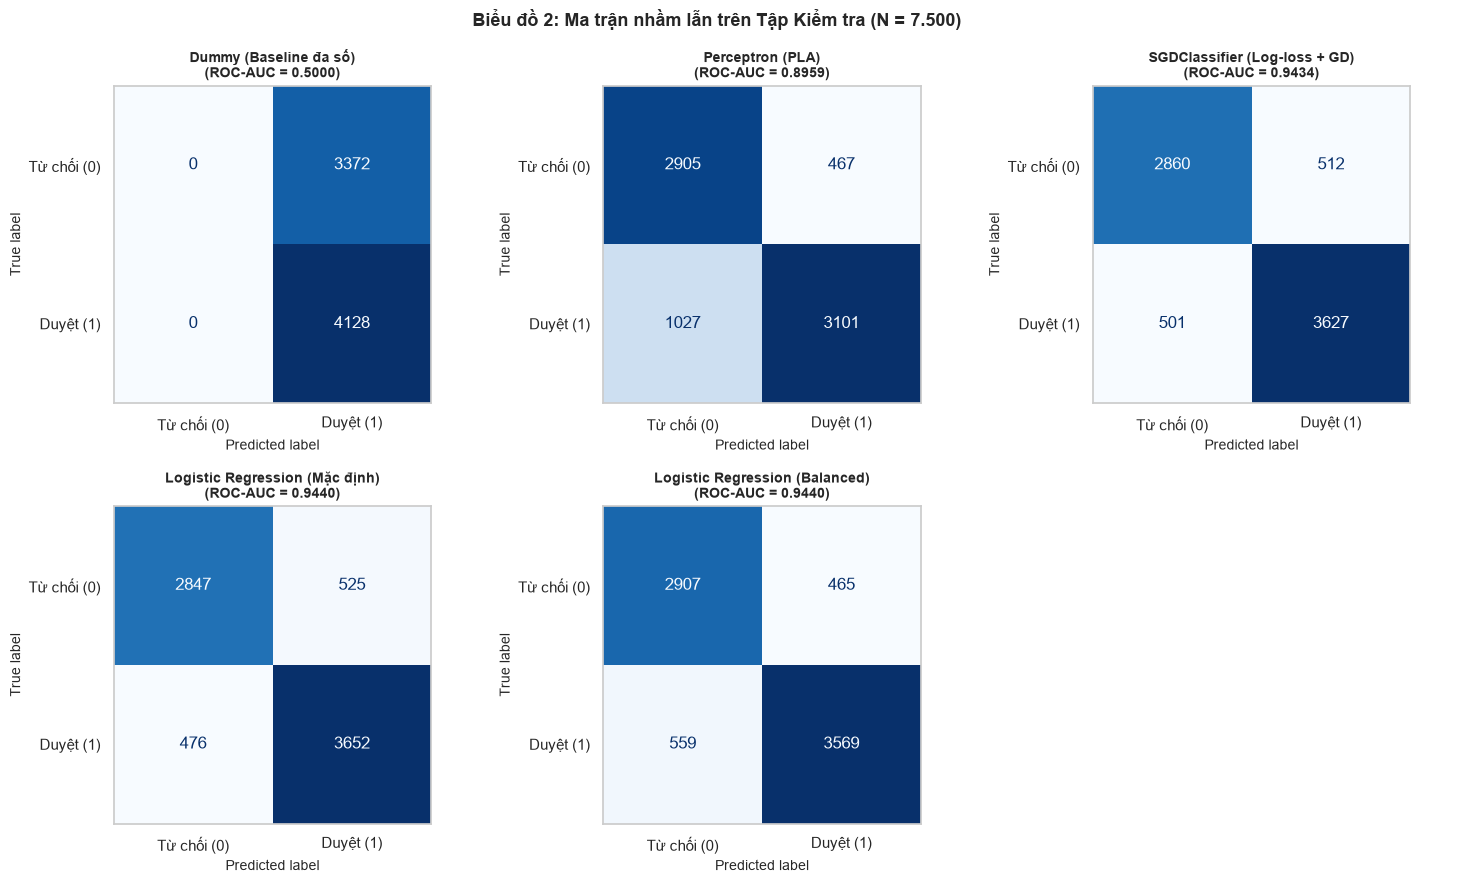

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes_flat = axes.ravel()

for idx, name in enumerate(fitted_pipelines):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_preds[name],
        display_labels=["Từ chối (0)", "Duyệt (1)"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=axes_flat[idx],
    )
    auc_val = roc_auc_score(y_test, y_scores[name])
    axes_flat[idx].set_title(f"{name}\n(ROC-AUC = {auc_val:.4f})", fontweight="bold", fontsize=10)
    axes_flat[idx].grid(False)

axes_flat[-1].axis("off")
plt.suptitle("Biểu đồ 2: Ma trận nhầm lẫn trên Tập Kiểm tra (N = 7.500)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(IMG_DIR / "ma_tran_nham_lan_cac_mo_hinh.png", dpi=90)
plt.show()

- **Cân bằng sai số:** `Logistic Regression (Mặc định)` phân loại đúng $3.652$ hồ sơ tốt (TP) và $2.847$ hồ sơ rủi ro (TN), mắc $525$ ca duyệt nhầm nợ xấu (FP) và $476$ ca từ chối nhầm (FN).
- **Lợi thế nhánh `Balanced`:** Khi dùng `class_weight='balanced'`, số ca FP giảm từ $525$ xuống còn $465$ hồ sơ (`Specificity` tăng từ $84{,}43\%$ lên $86{,}21\%$), đổi lại FN tăng lên $559$.

### 4. Đường cong ROC so sánh 5 mô hình (`RocCurveDisplay`)

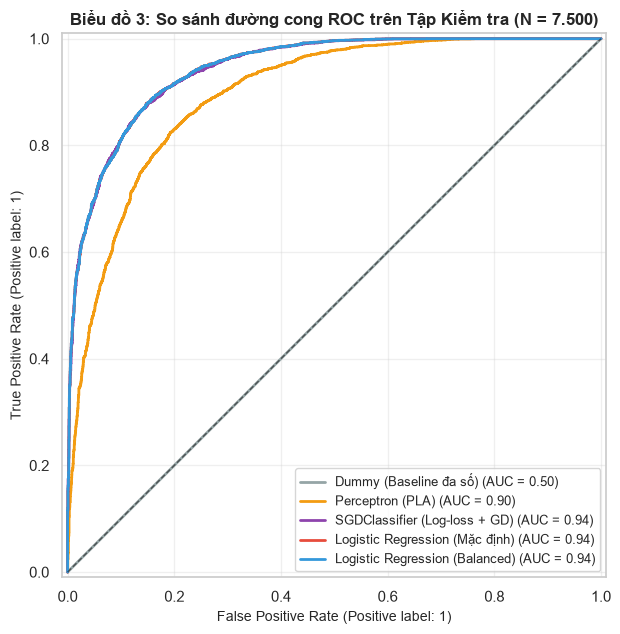

In [4]:
colors = ["#95a5a6", "#f39c12", "#8e44ad", "#e74c3c", "#3498db"]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for name, col in zip(fitted_pipelines, colors):
    disp = RocCurveDisplay.from_predictions(y_test, y_scores[name], name=name, ax=ax)
    disp.line_.set_color(col)
    disp.line_.set_linewidth(2.0)

ax.plot([0, 1], [0, 1], "k--", linewidth=1.0, alpha=0.6)
ax.set_title("Biểu đồ 3: So sánh đường cong ROC trên Tập Kiểm tra (N = 7.500)", fontweight="bold")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(IMG_DIR / "duong_cong_roc_so_sanh.png", dpi=90)
plt.show()

- **Khả năng xếp hạng:** Đường cong ROC của hai mô hình `Logistic Regression` ($\text{AUC} = 0{,}9440$) và `SGDClassifier` ($\text{AUC} = 0{,}9434$) gần như trùng khít, nằm cao sát góc trên bên trái và bỏ xa `Perceptron` ($0{,}8959$) cũng như đường chéo ngẫu nhiên `Dummy` ($0{,}5000$).

### 5. Đường cong Precision-Recall trên Tập Kiểm tra (`PrecisionRecallDisplay`)

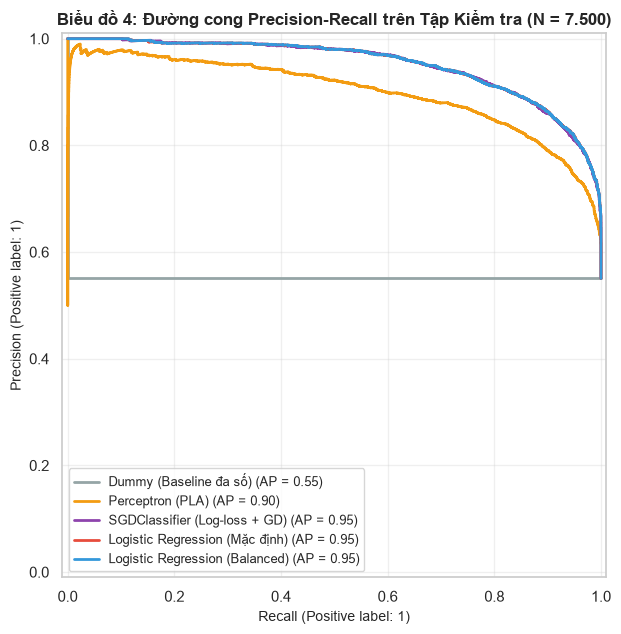

In [5]:
colors = ["#95a5a6", "#f39c12", "#8e44ad", "#e74c3c", "#3498db"]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for name, col in zip(fitted_pipelines, colors):
    disp = PrecisionRecallDisplay.from_predictions(y_test, y_scores[name], name=name, ax=ax)
    disp.line_.set_color(col)
    disp.line_.set_linewidth(2.0)

ax.set_title("Biểu đồ 4: Đường cong Precision-Recall trên Tập Kiểm tra (N = 7.500)", fontweight="bold")
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(IMG_DIR / "duong_cong_precision_recall.png", dpi=90)
plt.show()

- **Độ tin cậy dự đoán lớp duyệt:** Nhóm mô hình tối ưu hàm Log-loss đạt Average Precision `AP = 0,9519` (`Logistic Regression`) và `0,9515` (`SGDClassifier`), duy trì Precision cao ngay cả ở vùng Recall rộng so với mức nền `0,5504` của `Dummy`.